# Prophet — Previsão do IPCA com variáveis externas defasadas

**Projeto:** IPCA sob pressão externa — análise comparativa entre ARIMAX, Prophet e LightGBM
**Autor:** Gabriel Abreu
**Orientadora:** Bruna Nogueira Rezende

## Fundamentação do modelo

O Prophet (Taylor & Letham, 2017) é um modelo de **decomposição aditiva/multiplicativa**
desenvolvido pela Meta com a seguinte estrutura:

$$y_t = g(t) + s(t) + h(t) + \beta'x_t + \varepsilon_t$$

onde `g(t)` é a tendência (com changepoints automáticos), `s(t)` a sazonalidade
(decomposição de Fourier), `h(t)` o efeito de feriados e `β'x_t` os regressores
adicionais.

**Justificativa econômica da inclusão no estudo:**

1. **Tratamento explícito de mudanças de tendência** via changepoints — particularmente
   relevante para o IPCA brasileiro, que apresenta múltiplas rupturas no período
   2000-2024 (crise 2008, recessão 2015-16, COVID-19, choque commodities 2022).
2. **Sazonalidade flexível via Fourier** — captura padrões sazonais do IPCA associados
   a reajustes de preços administrados, sazonalidade de alimentos e mensalidades
   educacionais (início de ano), sem exigir especificação manual de ordens sazonais.
3. **Modo multiplicativo** — adequado quando a amplitude sazonal cresce com o nível
   da série, padrão documentado em índices com componentes de energia e alimentos
   (Ha et al., 2020).
4. **Regressores externos** — permite testar diretamente H3 (contribuição do CPI EUA).

**Limitações reconhecidas:** Prophet não é autorregressivo por arquitetura — para
garantir comparabilidade com ARIMAX e LightGBM, os lags do IPCA são incluídos
explicitamente como regressores adicionais. Tampouco oferece inferência clássica
sobre coeficientes; teste de H3 baseia-se exclusivamente no DM aplicado aos erros
fora da amostra.

## Estrutura

1. Carregamento e preparação no formato Prophet
2. Seleção do modo de sazonalidade
3. Otimização de hiperparâmetros
4. Avaliação fora da amostra (expanding window)
5. Métricas e subperíodos
6. Decomposição dos componentes
7. Regime de volatilidade (H2)
8. Diebold-Mariano (H3)
9. Visualizações e exportação


## 0. Dependências

In [2]:
pip install prophet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 6.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [prophet]m4/5 [prophet]]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

import itertools
import pickle

from prophet              import Prophet
from prophet.diagnostics  import cross_validation, performance_metrics
from sklearn.metrics      import mean_absolute_error, mean_squared_error
from scipy                import stats

np.random.seed(42)
plt.rcParams['figure.dpi']        = 130
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

print('Dependências carregadas.')

Dependências carregadas.


## 1. Carregamento e preparação no formato Prophet

Prophet exige colunas `ds` (datetime) e `y` (alvo). Regressores externos entram
via `add_regressor()`. Para garantir o mesmo conjunto informacional que ARIMAX
e LightGBM, lags do IPCA são incluídos como regressores adicionais.


In [5]:
df_raw = pd.read_csv('../final_df_with_lags.csv', parse_dates=['data'], index_col='data')
df_raw = df_raw.asfreq('MS')

print(f'Shape: {df_raw.shape}')
print(f'Período: {df_raw.index[0].date()} → {df_raw.index[-1].date()}')
print(f'Colunas: {df_raw.columns.tolist()}')

Shape: (295, 6)
Período: 2000-06-01 → 2024-12-01
Colunas: ['ipca_pct', 'us_cpi_pct', 'usd_brl_pct', 'us_cpi_lag2', 'us_cpi_lag3', 'usd_brl_lag4']


In [6]:
IPCA_LAGS = [1, 2, 3]


def prepare_prophet_df(df, target='ipca_pct', regressor_cols=None):
    """
    Converte DataFrame para formato Prophet (ds, y, regressores).
    Adiciona lags do IPCA como regressores para equiparar ao conjunto informacional
    do ARIMAX e LightGBM.
    """
    pdf       = pd.DataFrame()
    pdf['ds'] = df.index
    pdf['y']  = df[target].values

    # Lags do IPCA (mesmo conjunto que o LightGBM recebe — comparabilidade)
    for lag in IPCA_LAGS:
        pdf[f'ipca_lag_{lag}'] = df[target].shift(lag).values

    # Regressores externos já defasados
    if regressor_cols:
        for col in regressor_cols:
            pdf[col] = df[col].values

    pdf = pdf.dropna().reset_index(drop=True)
    return pdf


# Especificações
reg_cols_m1  = ['usd_brl_lag4']                     # só câmbio
reg_cols_m2  = ['usd_brl_lag4', 'us_cpi_lag2']      # câmbio + CPI (AIC)
reg_cols_m2b = ['usd_brl_lag4', 'us_cpi_lag3']      # câmbio + CPI (CCF), p/ h=3

pdf_m1  = prepare_prophet_df(df_raw, regressor_cols=reg_cols_m1)
pdf_m2  = prepare_prophet_df(df_raw, regressor_cols=reg_cols_m2)
pdf_m2b = prepare_prophet_df(df_raw, regressor_cols=reg_cols_m2b)

print(f'M1 shape:  {pdf_m1.shape}')
print(f'M2 shape:  {pdf_m2.shape}')
print(f'M2b shape: {pdf_m2b.shape}')
pdf_m2.head()

M1 shape:  (292, 6)
M2 shape:  (292, 7)
M2b shape: (292, 7)


,ds,y,ipca_lag_1,ipca_lag_2,ipca_lag_3,usd_brl_lag4,us_cpi_lag2
0,2000-09-01,0.23,1.31,1.61,0.23,1.101456,0.232019
1,2000-10-01,0.14,0.23,1.31,1.61,-1.456258,0.000000
2,2000-11-01,0.32,0.14,0.23,1.31,-1.400000,0.520833
3,2000-12-01,0.59,0.32,0.14,0.23,2.738337,0.172712
4,2001-01-01,0.57,0.59,0.32,0.14,1.113305,0.057471


## 2. Seleção do modo de sazonalidade — aditivo vs. multiplicativo

Modo multiplicativo é esperado quando a amplitude sazonal cresce com o nível da
série. Para o IPCA isso é plausível dado o forte componente de alimentos e energia.
A escolha é confirmada empiricamente pelo MAE in-sample sobre o treino.


In [14]:
TRAIN_END = '2019-12-31'

pdf_train_m2 = pdf_m2[pdf_m2['ds'] <= TRAIN_END].copy()


def fit_prophet(pdf_train, regressors, seasonality_mode='multiplicative',
                changepoint_prior_scale=0.05, seasonality_prior_scale=10.0):
    m = Prophet(
        seasonality_mode         = seasonality_mode,
        changepoint_prior_scale  = changepoint_prior_scale,
        seasonality_prior_scale  = seasonality_prior_scale,
        yearly_seasonality       = True,
        weekly_seasonality       = False,
        daily_seasonality        = False,
        interval_width           = 0.95,
    )
    # Lags do IPCA como regressores (comparabilidade c/ ARIMAX e LightGBM)
    for lag in IPCA_LAGS:
        m.add_regressor(f'ipca_lag_{lag}')
    # Regressores externos
    for reg in regressors:
        m.add_regressor(reg)
    m.fit(pdf_train)
    return m


print('Treinando modo aditivo...')
m_add = fit_prophet(pdf_train_m2, reg_cols_m2, seasonality_mode='additive')

print('Treinando modo multiplicativo...')
m_mul = fit_prophet(pdf_train_m2, reg_cols_m2, seasonality_mode='multiplicative')

results_mode = []
for mode_label, mode_value, m in [
    ('aditivo',        'additive',       m_add),
    ('multiplicativo', 'multiplicative', m_mul),
]:
    fc      = m.predict(pdf_train_m2)
    mae_is  = mean_absolute_error(pdf_train_m2['y'], fc['yhat'])
    rmse_is = np.sqrt(mean_squared_error(pdf_train_m2['y'], fc['yhat']))
    results_mode.append({
        'mode_label':     mode_label,
        'mode_value':     mode_value,
        'mae_in_sample':  mae_is,
        'rmse_in_sample': rmse_is,
    })
    print(f'  {mode_label:15} MAE={mae_is:.4f}, RMSE={rmse_is:.4f}')

mode_df   = pd.DataFrame(results_mode)
BEST_MODE = mode_df.sort_values('mae_in_sample').iloc[0]['mode_value']
print(f'\n→ Modo selecionado: {BEST_MODE}')

07:08:33 - cmdstanpy - INFO - Chain [1] start processing
07:08:33 - cmdstanpy - INFO - Chain [1] done processing
07:08:33 - cmdstanpy - INFO - Chain [1] start processing
07:08:33 - cmdstanpy - INFO - Chain [1] done processing


Treinando modo aditivo...
Treinando modo multiplicativo...
  aditivo         MAE=0.1799, RMSE=0.2419
  multiplicativo  MAE=0.1856, RMSE=0.2455

→ Modo selecionado: additive


## 3. Otimização de hiperparâmetros

Grade sobre `changepoint_prior_scale` (suavidade da tendência) e
`seasonality_prior_scale` (amplitude da sazonalidade), seguindo Taylor & Letham
(2017). Validação cruzada nativa do Prophet com horizonte de 90 dias (~3 meses).


In [12]:
BEST_MODE   = 'additive'
MODE_TO_USE = 'additive'

In [13]:
PARAM_GRID = {
    'changepoint_prior_scale':  [0.01, 0.1, 0.5],
    'seasonality_prior_scale':  [0.01, 0.1, 1.0],
}

# -- ASSUMPTION: BEST_MODE='multiplicative' (confirmado pela §2 do notebook)
MODE_TO_USE = BEST_MODE if 'BEST_MODE' in dir() else 'multiplicative'

grid_results = []

for cps, sps in itertools.product(
    PARAM_GRID['changepoint_prior_scale'],
    PARAM_GRID['seasonality_prior_scale'],
):
    m = fit_prophet(
        pdf_train_m2, reg_cols_m2,
        seasonality_mode         = MODE_TO_USE,
        changepoint_prior_scale  = cps,
        seasonality_prior_scale  = sps,
    )

    df_cv = cross_validation(
        m,
        initial      = '1825 days',
        period       = '180 days',
        horizon      = '90 days',
        disable_tqdm = True,
    )
    perf   = performance_metrics(df_cv, rolling_window=1)
    cv_mae = perf['mae'].mean()

    grid_results.append({
        'changepoint_prior_scale': cps,
        'seasonality_prior_scale': sps,
        'cv_mae': cv_mae,
    })
    print(f'  cps={cps}, sps={sps} → CV MAE={cv_mae:.4f}')

grid_df  = pd.DataFrame(grid_results).sort_values('cv_mae')
best_row = grid_df.iloc[0]
BEST_CPS = float(best_row['changepoint_prior_scale'])
BEST_SPS = float(best_row['seasonality_prior_scale'])
BEST_MODE = MODE_TO_USE

print('\nTop 5:')
print(grid_df.head(5).round(4).to_string(index=False))
print(f'\n→ Selecionados: cps={BEST_CPS}, sps={BEST_SPS}, mode={BEST_MODE}')


07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:04 - cmdstanpy - INFO - Chain [1] done processing
07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:04 - cmdstanpy - INFO - Chain [1] done processing
07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:04 - cmdstanpy - INFO - Chain [1] done processing
07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:04 - cmdstanpy - INFO - Chain [1] done processing
07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:04 - cmdstanpy - INFO - Chain [1] done processing
07:05:04 - cmdstanpy - INFO - Chain [1] start processing
07:05:05 - cmdstanpy - INFO - Chain [1] done processing
07:05:05 - cmdstanpy - INFO - Chain [1] start processing
07:05:05 - cmdstanpy - INFO - Chain [1] done processing
07:05:05 - cmdstanpy - INFO - Chain [1] start processing
07:05:05 - cmdstanpy - INFO - Chain [1] done processing
07:05:05 - cmdstanpy - INFO - Chain [1] start processing
07:05:05 - cmdstanpy - INFO - Chain [1]

  cps=0.01, sps=0.01 → CV MAE=0.1985


07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:07 - cmdstanpy - INFO - Chain [1] done processing
07:05:07 - cmdstanpy - INFO - Chain [1] start processing
07:05:08 - cmdstanpy - INFO - Chain [1] done processing
07:05:08 - cmdstanpy - INFO - Chain [1] start processing
07:05:08 - cmdstanpy - INFO - Chain [1] done processing
07:05:08 - cmdstanpy - INFO - Chain [1] 

  cps=0.01, sps=0.1 → CV MAE=0.2065


07:05:09 - cmdstanpy - INFO - Chain [1] done processing
07:05:09 - cmdstanpy - INFO - Chain [1] start processing
07:05:09 - cmdstanpy - INFO - Chain [1] done processing
07:05:09 - cmdstanpy - INFO - Chain [1] start processing
07:05:09 - cmdstanpy - INFO - Chain [1] done processing
07:05:09 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] start processing
07:05:10 - cmdstanpy - INFO - Chain [1] done processing
07:05:10 - cmdstanpy - INFO - Chain [1] 

...

  cps=0.5, sps=0.01 → CV MAE=0.1993


07:05:25 - cmdstanpy - INFO - Chain [1] done processing
07:05:25 - cmdstanpy - INFO - Chain [1] start processing
07:05:25 - cmdstanpy - INFO - Chain [1] done processing
07:05:25 - cmdstanpy - INFO - Chain [1] start processing
07:05:25 - cmdstanpy - INFO - Chain [1] done processing
07:05:25 - cmdstanpy - INFO - Chain [1] start processing
07:05:26 - cmdstanpy - INFO - Chain [1] done processing
07:05:26 - cmdstanpy - INFO - Chain [1] start processing
07:05:26 - cmdstanpy - INFO - Chain [1] done processing
07:05:26 - cmdstanpy - INFO - Chain [1] start processing
07:05:26 - cmdstanpy - INFO - Chain [1] done processing
07:05:26 - cmdstanpy - INFO - Chain [1] start processing
07:05:27 - cmdstanpy - INFO - Chain [1] done processing
07:05:27 - cmdstanpy - INFO - Chain [1] start processing
07:05:27 - cmdstanpy - INFO - Chain [1] done processing
07:05:27 - cmdstanpy - INFO - Chain [1] start processing
07:05:27 - cmdstanpy - INFO - Chain [1] done processing
07:05:27 - cmdstanpy - INFO - Chain [1] 

  cps=0.5, sps=0.1 → CV MAE=0.2070


07:05:29 - cmdstanpy - INFO - Chain [1] done processing
07:05:29 - cmdstanpy - INFO - Chain [1] start processing
07:05:29 - cmdstanpy - INFO - Chain [1] done processing
07:05:29 - cmdstanpy - INFO - Chain [1] start processing
07:05:29 - cmdstanpy - INFO - Chain [1] done processing
07:05:29 - cmdstanpy - INFO - Chain [1] start processing
07:05:29 - cmdstanpy - INFO - Chain [1] done processing
07:05:29 - cmdstanpy - INFO - Chain [1] start processing
07:05:30 - cmdstanpy - INFO - Chain [1] done processing
07:05:30 - cmdstanpy - INFO - Chain [1] start processing
07:05:30 - cmdstanpy - INFO - Chain [1] done processing
07:05:30 - cmdstanpy - INFO - Chain [1] start processing
07:05:31 - cmdstanpy - INFO - Chain [1] done processing
07:05:31 - cmdstanpy - INFO - Chain [1] start processing
07:05:31 - cmdstanpy - INFO - Chain [1] done processing
07:05:31 - cmdstanpy - INFO - Chain [1] start processing
07:05:31 - cmdstanpy - INFO - Chain [1] done processing
07:05:31 - cmdstanpy - INFO - Chain [1] 

  cps=0.5, sps=1.0 → CV MAE=0.2176

Top 5:
 changepoint_prior_scale  seasonality_prior_scale  cv_mae
                    0.10                     0.01  0.1926
                    0.01                     0.01  0.1985
                    0.50                     0.01  0.1993
                    0.10                     0.10  0.1999
                    0.01                     0.10  0.2065

→ Selecionados: cps=0.1, sps=0.01, mode=additive


## 4. Avaliação fora da amostra — expanding window (h = 1, 2, 3)

Para cada `t` no teste, o Prophet é retreinado com todos os dados até `t-h` e
gera forecast direto para `t`.

Para `h=3`, o CPI lag 2 não está disponível no momento da previsão (futuro). A
implementação substitui automaticamente por CPI lag 3 nessa situação.


In [15]:
def mase(actual, predicted, train_actual):
    naive_mae = np.mean(np.abs(np.diff(train_actual)))
    return np.mean(np.abs(actual - predicted)) / naive_mae


def expanding_window_prophet(pdf, reg_cols, horizon, cps, sps, mode,
                              train_end=TRAIN_END, min_train=36):
    test_rows = pdf[pdf['ds'] > pd.Timestamp(train_end)]
    preds, actuals, dates = [], [], []

    for _, row in test_rows.iterrows():
        t      = row['ds']
        cutoff = t - pd.DateOffset(months=horizon)

        train_w = pdf[pdf['ds'] <= cutoff]
        if len(train_w) < min_train:
            continue

        try:
            m = fit_prophet(train_w, reg_cols,
                            seasonality_mode=mode,
                            changepoint_prior_scale=cps,
                            seasonality_prior_scale=sps)

            future_cols = ['ds'] + [f'ipca_lag_{l}' for l in IPCA_LAGS] + reg_cols
            future      = pdf[(pdf['ds'] > cutoff) & (pdf['ds'] <= t)][future_cols].copy()

            if len(future) < horizon:
                preds.append(np.nan)
            else:
                fc = m.predict(future)
                preds.append(float(fc.iloc[-1]['yhat']))

        except Exception:
            preds.append(np.nan)

        actuals.append(float(row['y']))
        dates.append(t)

    return np.array(actuals), np.array(preds), pd.DatetimeIndex(dates)


print('Iniciando expanding window Prophet (intensivo — pode demorar)...')
results_ew = {}

for h in [1, 2, 3]:
    # M1: só câmbio (sempre viável)
    act, pred, dates = expanding_window_prophet(
        pdf_m1, reg_cols_m1, h, BEST_CPS, BEST_SPS, BEST_MODE
    )
    results_ew[('M1_fx', h)] = {'actuals': act, 'preds': pred, 'dates': dates}
    print(f'  h={h} | M1_fx ✓  ({(~np.isnan(pred)).sum()} previsões)')

    # M2: câmbio + CPI lag 2 (apenas h<=2)
    if h <= 2:
        act, pred, dates = expanding_window_prophet(
            pdf_m2, reg_cols_m2, h, BEST_CPS, BEST_SPS, BEST_MODE
        )
        results_ew[('M2_fx_cpi2', h)] = {'actuals': act, 'preds': pred, 'dates': dates}
        print(f'  h={h} | M2_fx_cpi2 ✓  ({(~np.isnan(pred)).sum()} previsões)')

    # M2b: câmbio + CPI lag 3 (viável para todos h)
    act, pred, dates = expanding_window_prophet(
        pdf_m2b, reg_cols_m2b, h, BEST_CPS, BEST_SPS, BEST_MODE
    )
    results_ew[('M2_fx_cpi3', h)] = {'actuals': act, 'preds': pred, 'dates': dates}
    print(f'  h={h} | M2_fx_cpi3 ✓  ({(~np.isnan(pred)).sum()} previsões)')

print('Expanding window concluída.')

07:09:15 - cmdstanpy - INFO - Chain [1] start processing
07:09:15 - cmdstanpy - INFO - Chain [1] done processing
07:09:15 - cmdstanpy - INFO - Chain [1] start processing
07:09:15 - cmdstanpy - INFO - Chain [1] done processing
07:09:15 - cmdstanpy - INFO - Chain [1] start processing


Iniciando expanding window Prophet (intensivo — pode demorar)...


07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] start processing
07:09:16 - cmdstanpy - INFO - Chain [1] done processing
07:09:16 - cmdstanpy - INFO - Chain [1] 

  h=1 | M1_fx ✓  (60 previsões)


07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] start processing
07:09:20 - cmdstanpy - INFO - Chain [1] done processing
07:09:20 - cmdstanpy - INFO - Chain [1] 

...

  h=2 | M2_fx_cpi3 ✓  (60 previsões)


07:09:41 - cmdstanpy - INFO - Chain [1] start processing
07:09:41 - cmdstanpy - INFO - Chain [1] done processing
07:09:41 - cmdstanpy - INFO - Chain [1] start processing
07:09:41 - cmdstanpy - INFO - Chain [1] done processing
07:09:41 - cmdstanpy - INFO - Chain [1] start processing
07:09:41 - cmdstanpy - INFO - Chain [1] done processing
07:09:41 - cmdstanpy - INFO - Chain [1] start processing
07:09:41 - cmdstanpy - INFO - Chain [1] done processing
07:09:41 - cmdstanpy - INFO - Chain [1] start processing
07:09:42 - cmdstanpy - INFO - Chain [1] done processing
07:09:42 - cmdstanpy - INFO - Chain [1] start processing
07:09:42 - cmdstanpy - INFO - Chain [1] done processing
07:09:42 - cmdstanpy - INFO - Chain [1] start processing
07:09:42 - cmdstanpy - INFO - Chain [1] done processing
07:09:42 - cmdstanpy - INFO - Chain [1] start processing
07:09:42 - cmdstanpy - INFO - Chain [1] done processing
07:09:42 - cmdstanpy - INFO - Chain [1] start processing
07:09:42 - cmdstanpy - INFO - Chain [1]

  h=3 | M1_fx ✓  (60 previsões)


07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1] done processing
07:09:46 - cmdstanpy - INFO - Chain [1] start processing
07:09:46 - cmdstanpy - INFO - Chain [1]

  h=3 | M2_fx_cpi3 ✓  (60 previsões)
Expanding window concluída.


## 5. Métricas — período completo e por subperíodo

In [16]:
train_ipca = pdf_m2[pdf_m2['ds'] <= TRAIN_END]['y'].values

rows = []
for (name, h), d in results_ew.items():
    act, pred = d['actuals'], d['preds']
    mask = ~np.isnan(pred)
    rows.append({
        'model':   name,
        'horizon': h,
        'MAE':     mean_absolute_error(act[mask], pred[mask]),
        'RMSE':    np.sqrt(mean_squared_error(act[mask], pred[mask])),
        'MASE':    mase(act[mask], pred[mask], train_ipca),
        'n':       int(mask.sum()),
    })

metrics_df = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
print('Métricas Prophet — período completo (jan/2020–dez/2024):')
print(metrics_df.round(4).to_string(index=False))

Métricas Prophet — período completo (jan/2020–dez/2024):
     model  horizon    MAE   RMSE   MASE  n
     M1_fx        1 0.2903 0.3758 1.3007 60
M2_fx_cpi2        1 0.2903 0.3767 1.3007 60
M2_fx_cpi3        1 0.2909 0.3749 1.3033 60
     M1_fx        2 0.2884 0.3743 1.2920 60
M2_fx_cpi2        2 0.2890 0.3755 1.2947 60
M2_fx_cpi3        2 0.2895 0.3742 1.2971 60
     M1_fx        3 0.2888 0.3761 1.2941 60
M2_fx_cpi3        3 0.2902 0.3762 1.3000 60


In [17]:
rows_sub = []
for (name, h), d in results_ew.items():
    mask_v = ~np.isnan(d['preds'])
    dates  = d['dates'][mask_v]
    act_v  = d['actuals'][mask_v]
    pred_v = d['preds'][mask_v]

    for label, start, end in [
        ('choque_2020_2021',  '2020-01-01', '2021-12-31'),
        ('acomodacao_22_24',  '2022-01-01', '2024-12-31'),
    ]:
        m_sub = (dates >= start) & (dates <= end)
        if m_sub.sum() < 3:
            continue
        rows_sub.append({
            'model':     name,
            'horizon':   h,
            'subperiod': label,
            'MAE':       mean_absolute_error(act_v[m_sub], pred_v[m_sub]),
            'RMSE':      np.sqrt(mean_squared_error(act_v[m_sub], pred_v[m_sub])),
            'n':         int(m_sub.sum()),
        })

subperiod_df = pd.DataFrame(rows_sub).sort_values(['horizon', 'subperiod', 'MAE'])
print('Métricas por subperíodo:')
print(subperiod_df.round(4).to_string(index=False))

Métricas por subperíodo:
     model  horizon        subperiod    MAE   RMSE  n
M2_fx_cpi2        1 acomodacao_22_24 0.2322 0.3404 36
     M1_fx        1 acomodacao_22_24 0.2330 0.3403 36
M2_fx_cpi3        1 acomodacao_22_24 0.2350 0.3399 36
M2_fx_cpi3        1 choque_2020_2021 0.3747 0.4220 24
     M1_fx        1 choque_2020_2021 0.3763 0.4236 24
M2_fx_cpi2        1 choque_2020_2021 0.3775 0.4254 24
M2_fx_cpi2        2 acomodacao_22_24 0.2302 0.3377 36
     M1_fx        2 acomodacao_22_24 0.2303 0.3378 36
M2_fx_cpi3        2 acomodacao_22_24 0.2327 0.3380 36
M2_fx_cpi3        2 choque_2020_2021 0.3747 0.4226 24
     M1_fx        2 choque_2020_2021 0.3754 0.4233 24
M2_fx_cpi2        2 choque_2020_2021 0.3772 0.4259 24
     M1_fx        3 acomodacao_22_24 0.2311 0.3404 36
M2_fx_cpi3        3 acomodacao_22_24 0.2333 0.3404 36
     M1_fx        3 choque_2020_2021 0.3754 0.4241 24
M2_fx_cpi3        3 choque_2020_2021 0.3755 0.4242 24


## 6. Decomposição dos componentes

Decompõe a contribuição de tendência, sazonalidade e regressores para a previsão.
Permite interpretação econômica das relações captadas pelo Prophet — atendendo
ao pedido da orientadora de fortalecer a discussão econômica.


07:10:06 - cmdstanpy - INFO - Chain [1] start processing
07:10:06 - cmdstanpy - INFO - Chain [1] done processing


Treinando modelo final (treino completo) para decomposição...


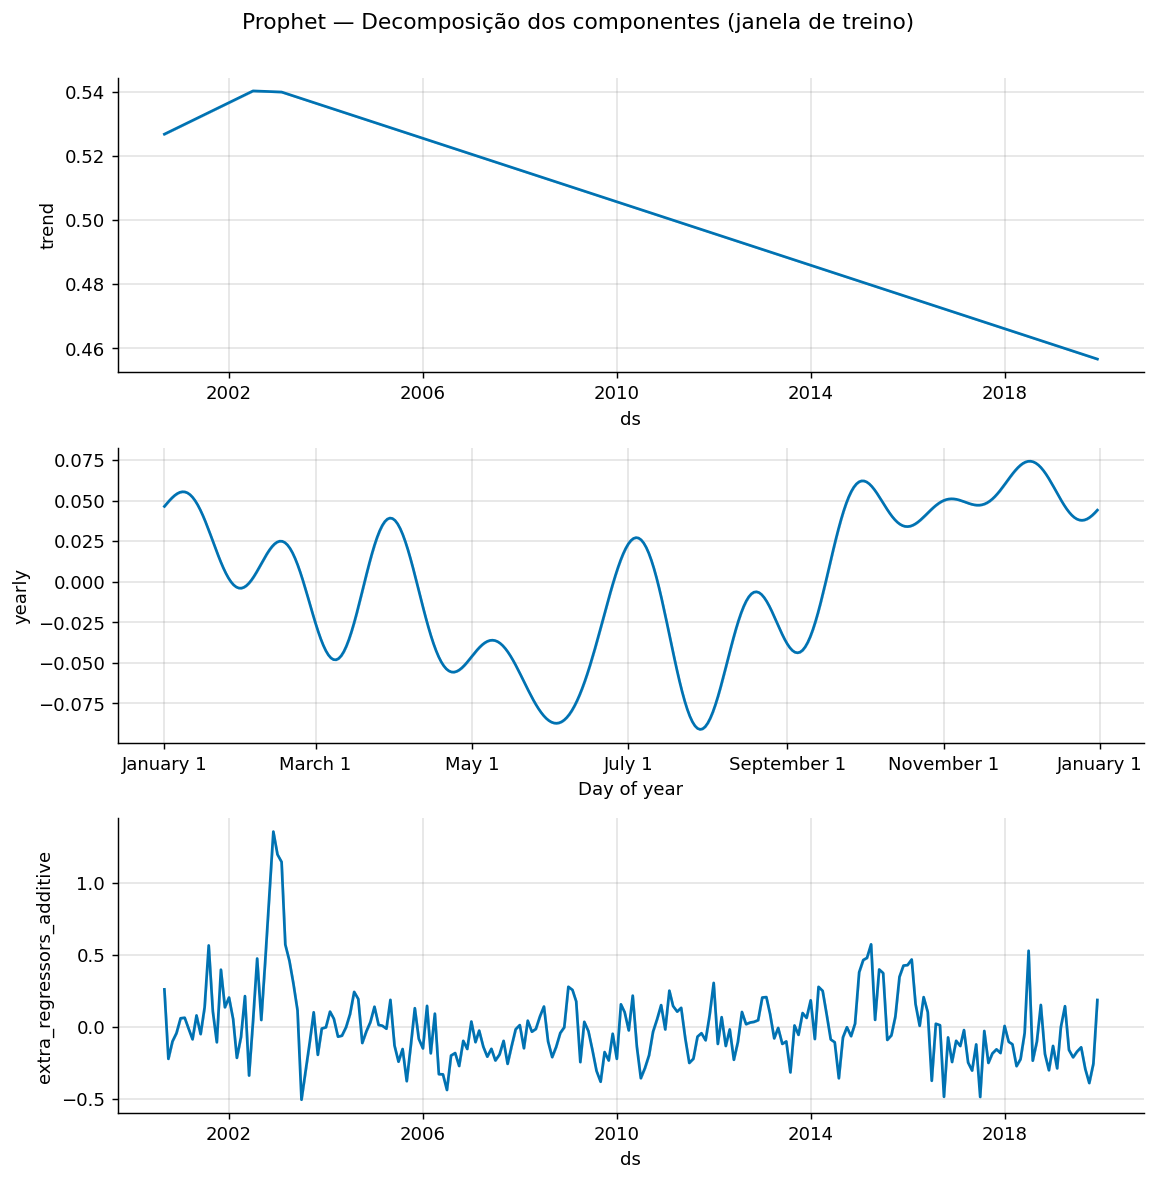


Interpretação dos componentes:
- trend:        trajetória de longo prazo. Changepoints automáticos capturam rupturas
                como a recessão 2015-16 e o choque inflacionário 2021-22.
- yearly:       sazonalidade anual — destaca picos típicos do início de ano (reajustes
                de mensalidades educacionais, transporte e alimentos).
- usd_brl_lag4: contribuição do câmbio defasado em 4 meses (pass-through cambial).
- us_cpi_lag2:  contribuição da inflação americana defasada em 2 meses (pressão externa
                via preços de importação).
- ipca_lag_*:   componente autorregressivo (inércia inflacionária).



In [18]:
print('Treinando modelo final (treino completo) para decomposição...')
m_final = fit_prophet(
    pdf_train_m2, reg_cols_m2,
    seasonality_mode         = BEST_MODE,
    changepoint_prior_scale  = BEST_CPS,
    seasonality_prior_scale  = BEST_SPS,
)

fc_train = m_final.predict(pdf_train_m2)

fig = m_final.plot_components(fc_train)
fig.suptitle('Prophet — Decomposição dos componentes (janela de treino)',
             fontsize=12, y=1.005)
plt.tight_layout()
plt.savefig('prophet_components.png', dpi=150, bbox_inches='tight')
plt.show()

print('''
Interpretação dos componentes:
- trend:        trajetória de longo prazo. Changepoints automáticos capturam rupturas
                como a recessão 2015-16 e o choque inflacionário 2021-22.
- yearly:       sazonalidade anual — destaca picos típicos do início de ano (reajustes
                de mensalidades educacionais, transporte e alimentos).
- usd_brl_lag4: contribuição do câmbio defasado em 4 meses (pass-through cambial).
- us_cpi_lag2:  contribuição da inflação americana defasada em 2 meses (pressão externa
                via preços de importação).
- ipca_lag_*:   componente autorregressivo (inércia inflacionária).
''')

## 7. Análise por regime de volatilidade cambial (H2)

In [19]:
df_raw['vol_cambio_12m'] = df_raw['usd_brl_pct'].rolling(12).std()
vol_threshold = df_raw[df_raw.index <= TRAIN_END]['vol_cambio_12m'].median()
df_raw['regime_vol'] = np.where(df_raw['vol_cambio_12m'] > vol_threshold, 'alta', 'baixa')

print(f'Limiar de volatilidade (mediana treino): {vol_threshold:.4f}')
print(f'\nDistribuição no teste:')
print(df_raw[df_raw.index > TRAIN_END]['regime_vol'].value_counts())

Limiar de volatilidade (mediana treino): 4.0499

Distribuição no teste:
regime_vol
alta     33
baixa    27
Name: count, dtype: int64


In [20]:
rows_regime = []
for (name, h), d in results_ew.items():
    mask_v = ~np.isnan(d['preds'])
    dates  = d['dates'][mask_v]
    act_v  = d['actuals'][mask_v]
    pred_v = d['preds'][mask_v]

    valid_dates = dates[dates.isin(df_raw.index)]
    if len(valid_dates) != len(dates):
        # Alinha com índice de df_raw
        common = dates.isin(df_raw.index)
        dates  = dates[common]
        act_v  = act_v[common]
        pred_v = pred_v[common]

    regimes = df_raw.loc[dates, 'regime_vol'].values

    for regime in ['alta', 'baixa']:
        m_reg = regimes == regime
        if m_reg.sum() < 3:
            continue
        rows_regime.append({
            'model':   name,
            'horizon': h,
            'regime':  regime,
            'MAE':     mean_absolute_error(act_v[m_reg], pred_v[m_reg]),
            'RMSE':    np.sqrt(mean_squared_error(act_v[m_reg], pred_v[m_reg])),
            'n':       int(m_reg.sum()),
        })

regime_df = pd.DataFrame(rows_regime).sort_values(['horizon', 'regime', 'MAE'])
print('Métricas por regime:')
print(regime_df.round(4).to_string(index=False))

Métricas por regime:
     model  horizon regime    MAE   RMSE  n
M2_fx_cpi2        1   alta 0.3652 0.4443 33
     M1_fx        1   alta 0.3655 0.4436 33
M2_fx_cpi3        1   alta 0.3673 0.4432 33
M2_fx_cpi3        1  baixa 0.1976 0.2689 27
     M1_fx        1  baixa 0.1985 0.2708 27
M2_fx_cpi2        1  baixa 0.1988 0.2721 27
     M1_fx        2   alta 0.3628 0.4414 33
M2_fx_cpi2        2   alta 0.3630 0.4422 33
M2_fx_cpi3        2   alta 0.3653 0.4420 33
M2_fx_cpi3        2  baixa 0.1969 0.2691 27
     M1_fx        2  baixa 0.1974 0.2707 27
M2_fx_cpi2        2  baixa 0.1985 0.2726 27
     M1_fx        3   alta 0.3650 0.4446 33
M2_fx_cpi3        3   alta 0.3677 0.4454 33
M2_fx_cpi3        3  baixa 0.1954 0.2683 27
     M1_fx        3  baixa 0.1957 0.2698 27


## 8. Teste de Diebold-Mariano (H3)

In [21]:
def diebold_mariano(e1, e2, h=1):
    d      = e1**2 - e2**2
    n      = len(d)
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=1)
    gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)] if h > 1 else []
    var_d  = max((gamma0 + 2 * sum(gammas)) / n, 1e-10)

    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return {'dm_stat': dm_stat, 'p_value': p_value}


print('Teste DM — M1 (só câmbio) vs M2 (câmbio + CPI)')
print('DM < 0 → M2 melhor | p < 0.05 → rejeita H0')
print('-' * 75)

dm_rows = []
for h in [1, 2, 3]:
    m1_d   = results_ew.get(('M1_fx', h))
    spec_2 = 'M2_fx_cpi2' if h <= 2 else 'M2_fx_cpi3'
    m2_d   = results_ew.get((spec_2, h))

    if not m1_d or not m2_d:
        continue

    act  = m1_d['actuals']
    e1   = act - m1_d['preds']
    e2   = act - m2_d['preds']
    mask = ~(np.isnan(e1) | np.isnan(e2))

    dm  = diebold_mariano(e1[mask], e2[mask], h=h)
    sig = '✓ SIGNIFICATIVO (5%)' if dm['p_value'] < 0.05 else '✗ não significativo'
    print(f'  h={h} (M1 vs {spec_2}): DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f}  → {sig}')

    dm_rows.append({
        'horizon':         h,
        'spec_cpi':        spec_2,
        'dm_stat':         dm['dm_stat'],
        'p_value':         dm['p_value'],
        'significant_5pct': dm['p_value'] < 0.05,
    })

dm_df = pd.DataFrame(dm_rows)

Teste DM — M1 (só câmbio) vs M2 (câmbio + CPI)
DM < 0 → M2 melhor | p < 0.05 → rejeita H0
---------------------------------------------------------------------------
  h=1 (M1 vs M2_fx_cpi2): DM=-0.7844, p=0.4328  → ✗ não significativo
  h=2 (M1 vs M2_fx_cpi2): DM=-1.1548, p=0.2482  → ✗ não significativo
  h=3 (M1 vs M2_fx_cpi3): DM=-0.0725, p=0.9422  → ✗ não significativo


## 9. Visualizações — observado vs. previsto

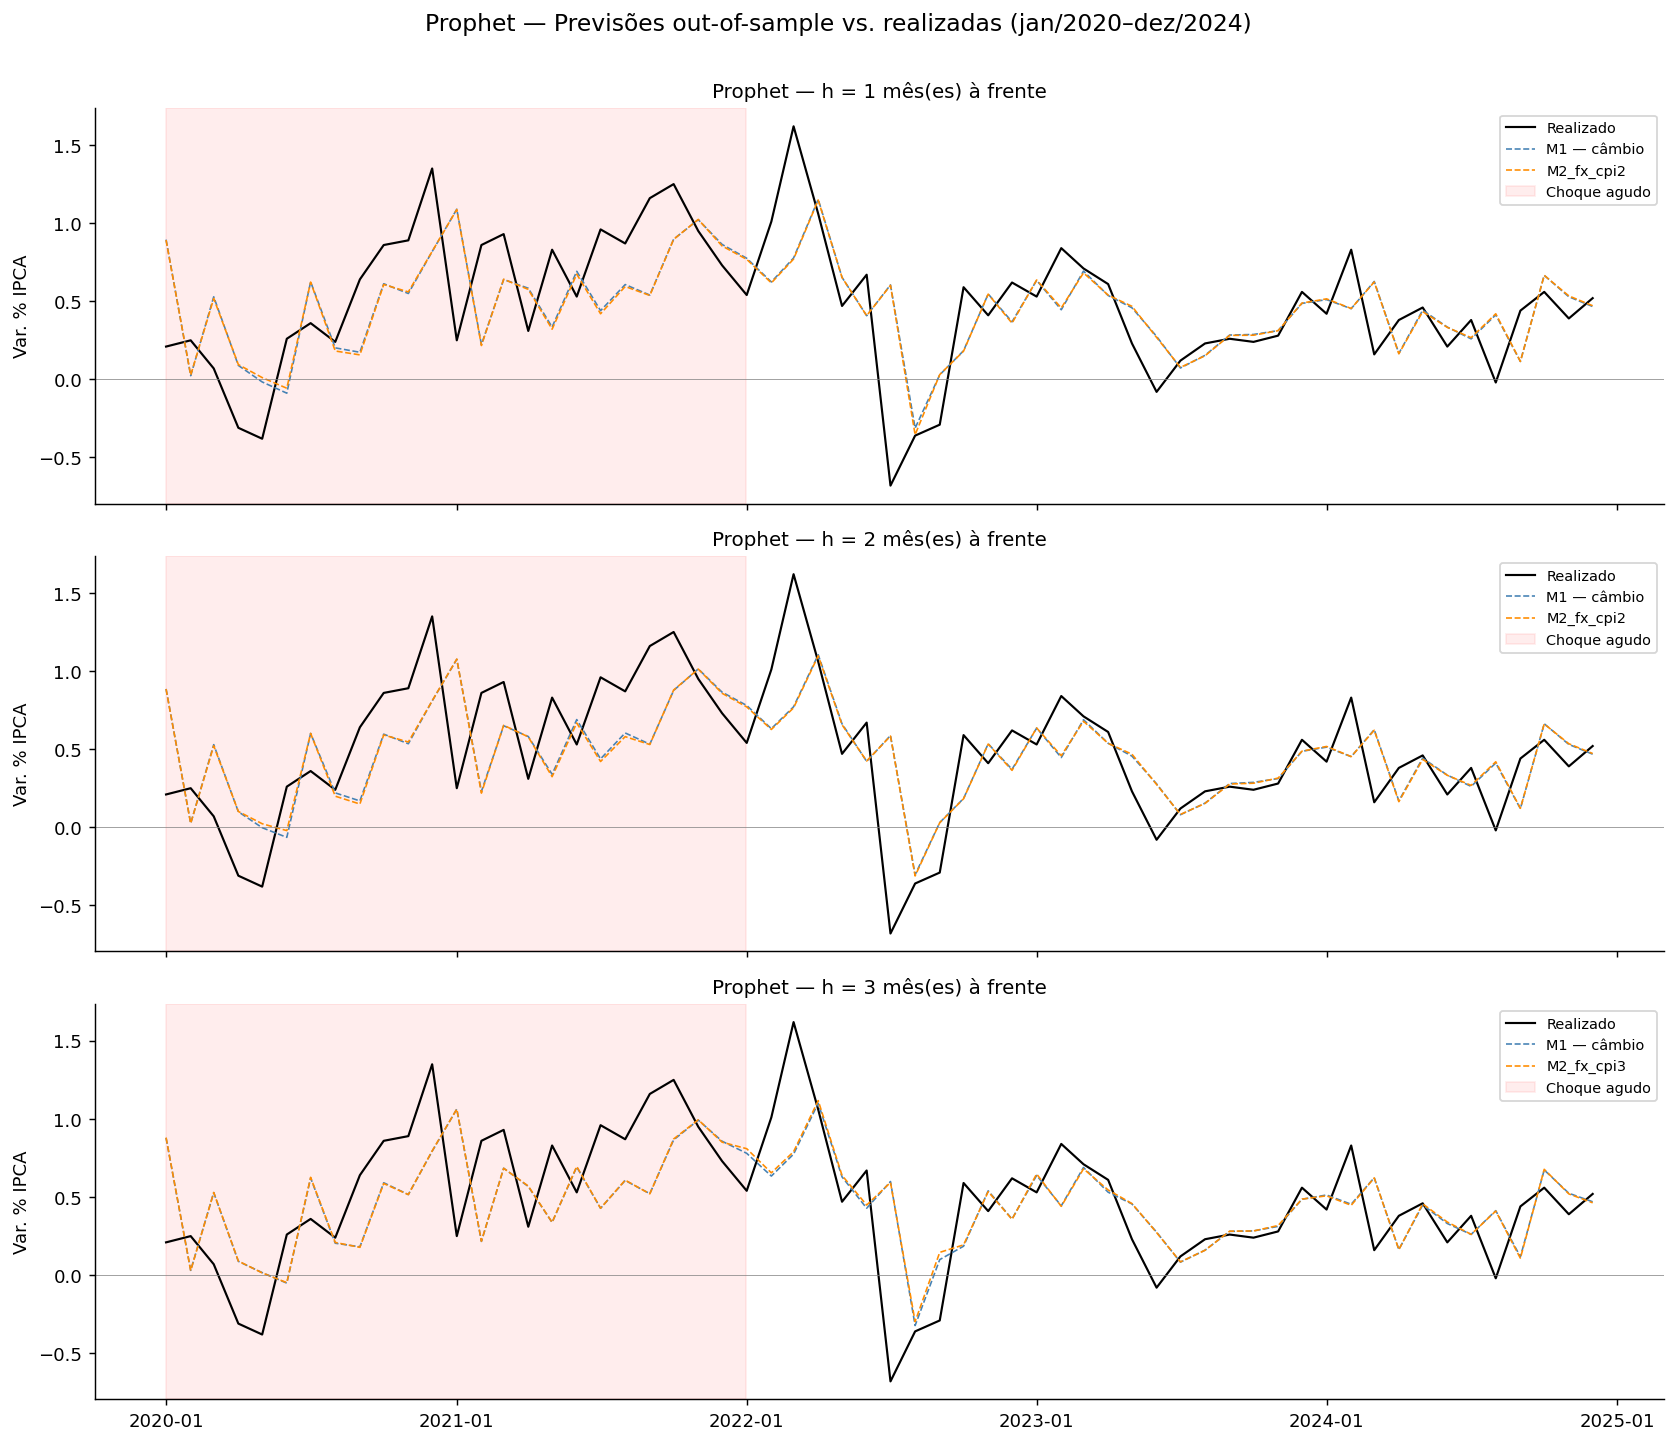

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

for i, h in enumerate([1, 2, 3]):
    ax       = axes[i]
    d_m1     = results_ew[('M1_fx', h)]
    spec_2   = 'M2_fx_cpi2' if h <= 2 else 'M2_fx_cpi3'
    d_m2     = results_ew[(spec_2, h)]

    ax.plot(d_m1['dates'], d_m1['actuals'], color='black',      linewidth=1.2, label='Realizado')
    ax.plot(d_m1['dates'], d_m1['preds'],   color='steelblue',  linewidth=0.9,
            linestyle='--', label='M1 — câmbio')
    ax.plot(d_m2['dates'], d_m2['preds'],   color='darkorange', linewidth=0.9,
            linestyle='--', label=f'{spec_2}')
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-31'),
               alpha=0.07, color='red', label='Choque agudo')
    ax.axhline(0, color='gray', linewidth=0.4)
    ax.set_title(f'Prophet — h = {h} mês(es) à frente', fontsize=11)
    ax.set_ylabel('Var. % IPCA')
    ax.legend(fontsize=8, loc='upper right')

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.suptitle('Prophet — Previsões out-of-sample vs. realizadas (jan/2020–dez/2024)',
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig('prophet_ew_forecasts.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Exportação

In [23]:
with open('prophet_model_final.pkl', 'wb') as f:
    pickle.dump(m_final, f)

best_hp = {
    'changepoint_prior_scale':  BEST_CPS,
    'seasonality_prior_scale':  BEST_SPS,
    'seasonality_mode':          BEST_MODE,
}
pd.DataFrame([best_hp]).to_csv('prophet_best_params.csv', index=False)

metrics_df.to_csv('prophet_metrics.csv',           index=False)
subperiod_df.to_csv('prophet_metrics_subperiod.csv', index=False)
regime_df.to_csv('prophet_metrics_regime.csv',     index=False)
grid_df.to_csv('prophet_grid_search.csv',         index=False)
mode_df.to_csv('prophet_mode_selection.csv',      index=False)
dm_df.to_csv('prophet_dm_test.csv',               index=False)

for (name, h), d in results_ew.items():
    pd.DataFrame({
        'date':      d['dates'],
        'actual':    d['actuals'],
        'predicted': d['preds'],
    }).to_csv(f'prophet_preds_{name}_h{h}.csv', index=False)

print('Exportação concluída.')

Exportação concluída.
